### Setup (Colab or local)

In [3]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/Varun-Ponugoti/DLAI.git"
PROJECT  = "generative"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    clone_dir = Path("/content/DLAI")
    if clone_dir.exists():
        subprocess.run(["git", "-C", str(clone_dir), "pull", "--ff-only"], check=False)
    else:
        subprocess.run(["git", "clone", REPO_URL, str(clone_dir)], check=True)
    repo = clone_dir / PROJECT
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(repo / "requirements.txt")], check=True)
    os.chdir(repo)
else:
    repo = Path.cwd().resolve()
    while not (repo / "src").is_dir() and repo != repo.parent:
        repo = repo.parent
    if not (repo / "src").is_dir():
        raise RuntimeError("Couldn't find the project folder (a folder containing src/).")

if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))
print("Project root:", repo, "| Colab:", IN_COLAB)

Project root: /content/DLAI/generative | Colab: True


### Environment & config

In [4]:
import json, time
import numpy as np
import torch
from PIL import Image
from IPython.display import display

from src.utils import REPO_ROOT, milestone_dir, get_device, environment_info

DEVICE, DTYPE = get_device()
ENV = environment_info(DEVICE, DTYPE)
ENV

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


{'device': 'cuda',
 'gpu': 'Tesla T4',
 'dtype': 'torch.float16',
 'versions': {'python': '3.13.16',
  'torch': '2.14.1+cu130',
  'diffusers': '0.31.0',
  'transformers': '4.46.3'}}

In [ ]:
OUT_DIR = milestone_dir("milestone2_conditioning")

MODEL_ID   = "stable-diffusion-v1-5/stable-diffusion-v1-5"  # fallback: "sd-legacy/stable-diffusion-v1-5"
SEED       = 42
IMAGE_SIZE = 512
NEG_PROMPT = "blurry, lowres, distorted, watermark, text"

print("Outputs:", OUT_DIR)

Outputs: /home/varun/Documents/Courses/Deep learning/DLAI/generative/outputs/milestone2_conditioning


### Text encoder integration

In [ ]:
from src.pipeline import load_text_encoder, load_diffusion_components, encode_prompt, generate
from src.utils import make_generator

tokenizer, text_encoder = load_text_encoder(MODEL_ID, DEVICE, DTYPE)
unet, vae, scheduler = load_diffusion_components(MODEL_ID, DEVICE, DTYPE)

def n_params(model):
    return f"{sum(p.numel() for p in model.parameters())/1e6:.0f}M"

print(f"Text encoder: {type(text_encoder).__name__:<22} {n_params(text_encoder)} params")
print(f"UNet        : {type(unet).__name__:<22} {n_params(unet)} params")
print(f"VAE         : {type(vae).__name__:<22} {n_params(vae)} params")
print(f"Scheduler   : {type(scheduler).__name__}")

/home/varun/Anaconda/ENTER/envs/deeplearning/lib/python3.10/site-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Text encoder: CLIPTextModel          123M params
UNet        : UNet2DConditionModel   860M params
VAE         : AutoencoderKL          84M params
Scheduler   : PNDMScheduler


In [ ]:
# The two dimensions that must match for text conditioning to work
text_dim = text_encoder.config.hidden_size
attn_dim = unet.config.cross_attention_dim
print(f"Text encoder hidden size : {text_dim}")
print(f"UNet cross-attention dim : {attn_dim}  -> {'match' if text_dim == attn_dim else 'MISMATCH'}")

# One UNet call, exactly as generate() does it
prompt = "a red apple on a wooden table"
text_emb = torch.cat([encode_prompt(NEG_PROMPT, tokenizer, text_encoder),
                      encode_prompt(prompt, tokenizer, text_encoder)])

latent_size = IMAGE_SIZE // 8
latents = torch.randn(2, unet.config.in_channels, latent_size, latent_size,
                      device=DEVICE, dtype=DTYPE)
t = torch.tensor(999, device=DEVICE)

with torch.no_grad():
    noise_pred = unet(latents, t, encoder_hidden_states=text_emb).sample

print(f"\nText embeddings  : {tuple(text_emb.shape)}   [uncond, cond] x 77 tokens x {text_dim}")
print(f"Latents in       : {tuple(latents.shape)}")
print(f"Noise prediction : {tuple(noise_pred.shape)}   same shape as the latents")

Text encoder hidden size : 768
UNet cross-attention dim : 768  -> match

Text embeddings  : (2, 77, 768)   [uncond, cond] x 77 tokens x 768
Latents in       : (2, 4, 64, 64)
Noise prediction : (2, 4, 64, 64)   same shape as the latents


### Verify the integration

Generated in 4.4s
Mean pixel difference vs. M1: 0.31 | max: 13  (0–255 scale)


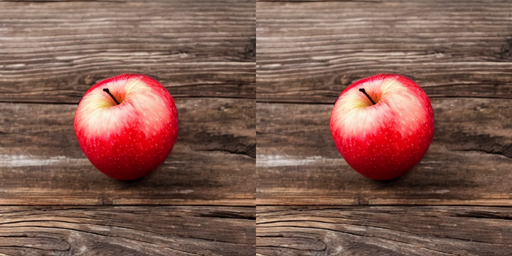

In [ ]:
BASE_GUIDANCE = 7.5
BASE_STEPS    = 30

start = time.time()
ours = generate(
    "a red apple on a wooden table",
    tokenizer, text_encoder, unet, vae, scheduler,
    negative_prompt=NEG_PROMPT,
    guidance_scale=BASE_GUIDANCE,
    num_steps=BASE_STEPS,
    height=IMAGE_SIZE, width=IMAGE_SIZE,
    generator=make_generator(SEED, DEVICE),
)
print(f"Generated in {time.time() - start:.1f}s")

m1 = Image.open(REPO_ROOT / "outputs/milestone1_baseline/images/p1_simple_object.png").convert("RGB")
diff = np.abs(np.asarray(ours, dtype=np.float32) - np.asarray(m1, dtype=np.float32))
print(f"Mean pixel difference vs. M1: {diff.mean():.2f} | max: {diff.max():.0f}  (0–255 scale)")

side_by_side = Image.new("RGB", (IMAGE_SIZE * 2, IMAGE_SIZE))
side_by_side.paste(ours, (0, 0))
side_by_side.paste(m1, (IMAGE_SIZE, 0))
display(side_by_side.resize((IMAGE_SIZE, IMAGE_SIZE // 2)))   # left: ours | right: M1 pipeline

### Baseline conditional generation

In [ ]:
from src.utils import make_grid, add_caption, save_run_log, write_gallery

PROMPTS = [
    ("p1_simple_object", "a red apple on a wooden table"),
    ("p2_multi_object",  "a cat and a dog sitting together on a park bench"),
    ("p3_spatial",       "a blue cube to the left of a yellow sphere on a white floor"),
    ("p4_stylistic",     "a mountain lake at sunrise, in the style of a watercolor painting"),
    ("p5_abstract",      "the feeling of nostalgia, surreal dreamlike digital art"),
]

RUNS = {}


def run_and_record(experiment, tag, prompt, *, guidance_scale=BASE_GUIDANCE,
                   num_steps=BASE_STEPS, sched=None, extra=None):
    sched = sched or scheduler
    start = time.time()
    img = generate(
        prompt, tokenizer, text_encoder, unet, vae, sched,
        negative_prompt=NEG_PROMPT,
        guidance_scale=guidance_scale,
        num_steps=num_steps,
        height=IMAGE_SIZE, width=IMAGE_SIZE,
        generator=make_generator(SEED, DEVICE),   # same seed for every image
    )
    seconds = round(time.time() - start, 2)

    (OUT_DIR / experiment).mkdir(exist_ok=True)
    rel_path = f"{experiment}/{tag}.png"
    img.save(OUT_DIR / rel_path)

    RUNS[rel_path] = {
        "experiment": experiment,
        "tag": tag,
        "prompt": prompt,
        "negative_prompt": NEG_PROMPT,
        "seed": SEED,
        "steps": num_steps,
        "guidance_scale": guidance_scale,
        "scheduler": type(sched).__name__,
        "height": IMAGE_SIZE,
        "width": IMAGE_SIZE,
        "seconds": seconds,
        "image": rel_path,
        **(extra or {}),
    }
    return img


def save_records():
    save_run_log(OUT_DIR, ENV, RUNS, model_id=MODEL_ID)
    write_gallery(OUT_DIR, RUNS, "Milestone 2 — Conditional generation")

In [ ]:
baseline_images = []
for tag, prompt in PROMPTS:
    img = run_and_record("baseline", tag, prompt)
    baseline_images.append(img)
    print(f"[{RUNS[f'baseline/{tag}.png']['seconds']:>5.1f}s] {tag}")

baseline_grid = make_grid([add_caption(img, tag) for img, (tag, _) in zip(baseline_images, PROMPTS)],
                          cols=len(PROMPTS))
baseline_grid.save(OUT_DIR / "baseline" / "grid.png")
save_records()
print("Saved to", OUT_DIR / "baseline")

[  4.4s] p1_simple_object
[  4.4s] p2_multi_object
[  4.4s] p3_spatial
[  4.4s] p4_stylistic
[  4.5s] p5_abstract
Saved to /home/varun/Documents/Courses/Deep learning/DLAI/generative/outputs/milestone2_conditioning/baseline


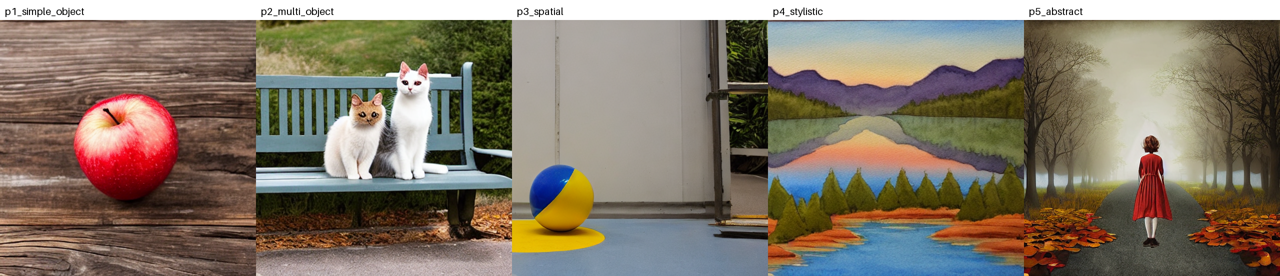

In [ ]:
display(baseline_grid.resize((baseline_grid.width // 2, baseline_grid.height // 2)))

### Noise schedule / sampler sweep
The five baseline prompts through PNDM, DDIM and DPM-Solver (`src/schedulers.py`) with seed, steps and guidance fixed. Writes images, `grid.png`, `run_log.json` and `GALLERY.md` to `outputs/milestone2_conditioning/noise_sweep/`.

In [5]:
# ============================================================
# M2 — Noise-schedule / sampler sweep  (PNDM vs DDIM vs DPM-Solver)
# Varies ONLY the sampler. Prompts, seed, steps and guidance are read from
# the baseline run log and kept identical across samplers. Run without a
# negative prompt (the baseline above uses NEG_PROMPT), so the PNDM images
# are not pixel-identical to the baseline. Writes to its own noise_sweep/
# folder; nothing existing is overwritten.
# ============================================================
import json, time, torch
from src import utils as U
from src import pipeline as P
from src import schedulers as S

DEVICE, DTYPE = U.get_device()
print("Device:", DEVICE, DTYPE)

# Pull the 5 baseline prompts + their exact settings from the committed log
m2_dir = U.milestone_dir("milestone2_conditioning")
blog = json.loads((m2_dir / "run_log.json").read_text())
MODEL_ID = blog.get("model_id", "stable-diffusion-v1-5/stable-diffusion-v1-5")

base = {}
for r in blog.get("runs", []):
    key = r["tag"].split("_cfg")[0]        # strip any guidance-sweep suffix
    if key not in base:
        base[key] = {
            "prompt":   r["prompt"],
            "seed":     int(r.get("seed", 42)),
            "steps":    int(r.get("steps", 30)),
            "guidance": float(r.get("guidance_scale", 7.5)),
        }
print(f"Loaded {len(base)} baseline prompts:", list(base))

SWEEP = ["pndm", "ddim", "dpm"]            # >=3 samplers; pndm == baseline reference

# Load model once
tokenizer, text_encoder = P.load_text_encoder(MODEL_ID, DEVICE, DTYPE)
unet, vae, _ = P.load_diffusion_components(MODEL_ID, DEVICE, DTYPE)

out_dir = m2_dir / "noise_sweep"
out_dir.mkdir(parents=True, exist_ok=True)

runs, grid_imgs = {}, []
for key, cfg in base.items():
    for name in SWEEP:
        sched = S.load_scheduler(name, MODEL_ID)      # fresh scheduler per image
        gen = U.make_generator(cfg["seed"], DEVICE)   # identical starting noise
        t0 = time.time()
        img = P.generate(
            cfg["prompt"], tokenizer, text_encoder, unet, vae, sched,
            negative_prompt="",   # as run; baseline uses NEG_PROMPT
            guidance_scale=cfg["guidance"], num_steps=cfg["steps"], generator=gen,
        )
        dt = round(time.time() - t0, 2)
        tag, fname = f"{key}_{name}", f"{key}_{name}.png"
        img.save(out_dir / fname)
        grid_imgs.append(U.add_caption(img, f"{key} | {name}"))
        runs[tag] = {
            "experiment": "noise_sweep", "tag": tag, "prompt": cfg["prompt"],
            "scheduler": name, "steps": cfg["steps"],
            "guidance_scale": cfg["guidance"], "seed": cfg["seed"],
            "seconds": dt, "image": fname,
        }
        print(f"  {tag}  ({dt}s)")

U.make_grid(grid_imgs, cols=len(SWEEP)).save(out_dir / "grid.png")
env = U.environment_info(DEVICE, DTYPE)
U.save_run_log(out_dir, env, runs, experiment="noise_sweep",
               model_id=MODEL_ID, samplers=SWEEP)
U.write_gallery(out_dir, runs, "M2 - Noise-schedule / sampler sweep")
print(f"\nDone: {len(runs)} images -> {out_dir}")

Device: cuda torch.float16
Loaded 5 baseline prompts: ['p1_simple_object', 'p2_multi_object', 'p3_spatial', 'p4_stylistic', 'p5_abstract']


  p1_simple_object_pndm  (6.58s)
  p1_simple_object_ddim  (4.43s)
  p1_simple_object_dpm  (4.42s)
  p2_multi_object_pndm  (4.59s)
  p2_multi_object_ddim  (4.48s)
  p2_multi_object_dpm  (4.47s)
  p3_spatial_pndm  (4.68s)
  p3_spatial_ddim  (4.58s)
  p3_spatial_dpm  (4.58s)
  p4_stylistic_pndm  (4.77s)
  p4_stylistic_ddim  (4.66s)
  p4_stylistic_dpm  (4.66s)
  p5_abstract_pndm  (4.89s)
  p5_abstract_ddim  (4.78s)
  p5_abstract_dpm  (4.76s)

Done: 15 images -> /content/DLAI/generative/outputs/milestone2_conditioning/noise_sweep


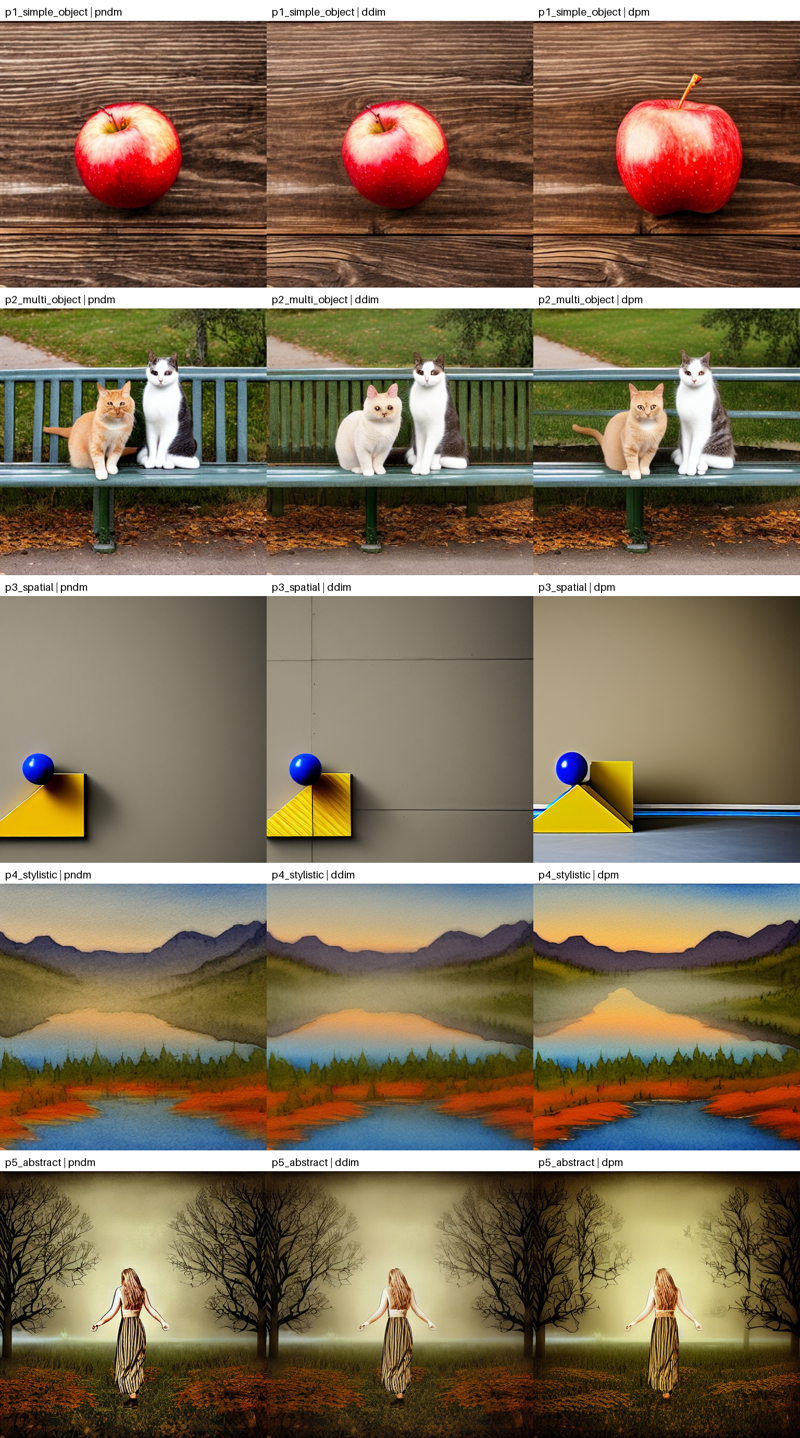

In [6]:
# Preview the sampler-sweep grid (rows = prompts, columns = PNDM / DDIM / DPM-Solver)
from IPython.display import display
from PIL import Image
grid = Image.open(out_dir / "grid.png")
grid.thumbnail((800, 1440))
display(grid)